<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/LR_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Реализовать класс логистической регрессии для многоклассовой классификации изображений MNIST, Fashion-MNIST и CIFAR-10. Выполнить нормализацию данных, реализовать классификацию One-vs-All с помощью градиентного спуска и L2-регуляризации, оценить точность и время работы, показать примеры ошибочной классификации и визуализировать веса модели.

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import gc
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

np.random.seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.22.0-rc1


In [ ]:
class LR:
    def __init__(self, alpha=2.5, epsilon=1e-4, max_iter=1000, reg_param=1.0):
        self.alpha = alpha
        self.epsilon = epsilon
        self.max_iter = max_iter
        self.reg_param = reg_param
        self.W = None
        self.n_iter_ = 0

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -50.0, 50.0)
        return 1.0 / (1.0 + np.exp(-z))

    @classmethod
    def set_data(cls, dataset_name):
        if dataset_name == "MNIST":
            (x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
            class_names = [str(i) for i in range(10)]
        elif dataset_name == "Fashion-MNIST":
            (x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
            class_names = [
                "Футболка", "Брюки", "Пуловер", "Платье", "Пальто",
                "Сандалии", "Рубашка", "Кроссовки", "Сумка", "Ботильоны"
            ]
        elif dataset_name == "CIFAR-10":
            (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
            class_names = [
                "Самолёт", "Автомобиль", "Птица", "Кошка", "Олень",
                "Собака", "Лягушка", "Лошадь", "Корабль", "Грузовик"
            ]
        else:
            raise ValueError("Неизвестный набор данных: " + str(dataset_name))

        y_train = np.asarray(y_train).reshape(-1).astype(np.int64)
        y_test = np.asarray(y_test).reshape(-1).astype(np.int64)
        image_shape = tuple(x_train.shape[1:])

        x_test_images = x_test.copy()

        def prepare_features(images):
            count = images.shape[0]
            features_count = int(np.prod(images.shape[1:]))
            X = np.empty((count, features_count + 1), dtype=np.float32)
            X[:, 0] = 1.0
            X[:, 1:] = images.reshape(count, features_count)
            X[:, 1:] /= 255.0
            return X

        X_train = prepare_features(x_train)
        X_test = prepare_features(x_test)

        del x_train, x_test
        gc.collect()

        print(f"{dataset_name}: обучение {X_train.shape[0]} изображений, "
              f"тестирование {X_test.shape[0]} изображений, "
              f"признаков {X_train.shape[1] - 1}")

        return X_train, y_train, X_test, y_test, x_test_images, image_shape, class_names

    def grad(self, X, Y):
        H = self.sigmoid(X @ self.W)
        gradient = X.T @ (H - Y)
        gradient[1:, :] += self.reg_param * self.W[1:, :]
        gradient /= X.shape[0]
        return gradient

    def cost(self, X, Y):
        H = self.sigmoid(X @ self.W)
        eps = 1e-7
        data_loss = -np.sum(
            Y * np.log(H + eps) + (1.0 - Y) * np.log(1.0 - H + eps),
            dtype=np.float64
        ) / X.shape[0]
        regularization = (
            self.reg_param * np.sum(self.W[1:, :] ** 2, dtype=np.float64)
            / (2.0 * X.shape[0])
        )
        return data_loss + regularization

    def fit(self, X_train, y_train):
        m = X_train.shape[0]
        n_classes = int(np.max(y_train)) + 1
        Y = np.eye(n_classes, dtype=np.float32)[y_train]

        self.W = np.zeros((X_train.shape[1], n_classes), dtype=np.float32)

        for iteration in range(1, self.max_iter + 1):
            gradient = self.grad(X_train, Y)
            W_next = self.W - self.alpha * gradient
            change = np.max(np.abs(W_next - self.W))
            self.W = W_next
            self.n_iter_ = iteration

            if iteration % 100 == 0 or iteration == 1:
                print(
                    f"Итерация {iteration}/{self.max_iter}; "
                    f"функция потерь: {self.cost(X_train, Y):.5f}"
                )

            if change < self.epsilon:
                print(f"Сходимость достигнута на итерации {iteration}.")
                break

        return self

    def one_vs_all(self, X_train, y_train):
        return self.fit(X_train, y_train)

    def predict_proba(self, X):
        if self.W is None:
            raise RuntimeError("Сначала необходимо обучить модель методом fit().")
        return self.sigmoid(X @ self.W)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def accuracy(self, X_test, y_test):
        predictions = self.predict(X_test)
        return float(np.mean(predictions == y_test) * 100.0)

    def depict(self, test_images, y_test, predictions, image_shape, class_names):
        mismatches = np.flatnonzero(predictions != y_test)
        print("Количество ошибок:", len(mismatches))

        count = min(10, len(mismatches))
        if count:
            fig, axes = plt.subplots(1, count, figsize=(2.5 * count, 3))
            if count == 1:
                axes = [axes]

            for ax, index in zip(axes, mismatches[:count]):
                true_label = int(y_test[index])
                predicted_label = int(predictions[index])
                image = test_images[index]

                if len(image_shape) == 2:
                    ax.imshow(image, cmap="gray")
                else:
                    ax.imshow(image)

                ax.set_title(
                    f"Правильно: {class_names[true_label]}\n"
                    f"Прогноз: {class_names[predicted_label]}",
                    fontsize=9
                )
                ax.axis("off")

            plt.tight_layout()
            plt.show()
        else:
            print("Ошибочных классификаций нет.")

        weights = self.W[1:, :].T.reshape((self.W.shape[1],) + image_shape)
        fig, axes = plt.subplots(2, 5, figsize=(15, 6))

        for class_index, ax in enumerate(axes.flat):
            weight_image = weights[class_index]

            if len(image_shape) == 2:
                limit = np.max(np.abs(weight_image)) + 1e-8
                ax.imshow(weight_image, cmap="coolwarm", vmin=-limit, vmax=limit)
            else:
                scale = np.max(np.abs(weight_image), axis=(0, 1), keepdims=True) + 1e-8
                visible_weights = np.clip(0.5 + 0.5 * weight_image / scale, 0.0, 1.0)
                ax.imshow(visible_weights)

            ax.set_title(class_names[class_index], fontsize=9)
            ax.axis("off")

        plt.suptitle("Весовые коэффициенты классификаторов One-vs-All")
        plt.tight_layout()
        plt.show()


НАБОР ДАННЫХ: MNIST
MNIST: обучение 60000 изображений, тестирование 10000 изображений, признаков 784
Итерация 1/1000; функция потерь: 16.06744
Итерация 100/1000; функция потерь: 1.01992
Итерация 200/1000; функция потерь: 0.90847
Итерация 300/1000; функция потерь: 0.82932
Итерация 400/1000; функция потерь: 0.79607
Итерация 500/1000; функция потерь: 0.77725
Итерация 600/1000; функция потерь: 0.78215
Итерация 700/1000; функция потерь: 0.97736
Итерация 800/1000; функция потерь: 0.74576
Итерация 900/1000; функция потерь: 0.73563
Итерация 1000/1000; функция потерь: 0.75077

Точность: 90.72%
Правильно распознано: 9072 из 10000
Количество ошибок: 928
Итераций: 1000
Время загрузки и подготовки: 0.27 сек.
Время обучения: 45.25 сек.
Количество ошибок: 928


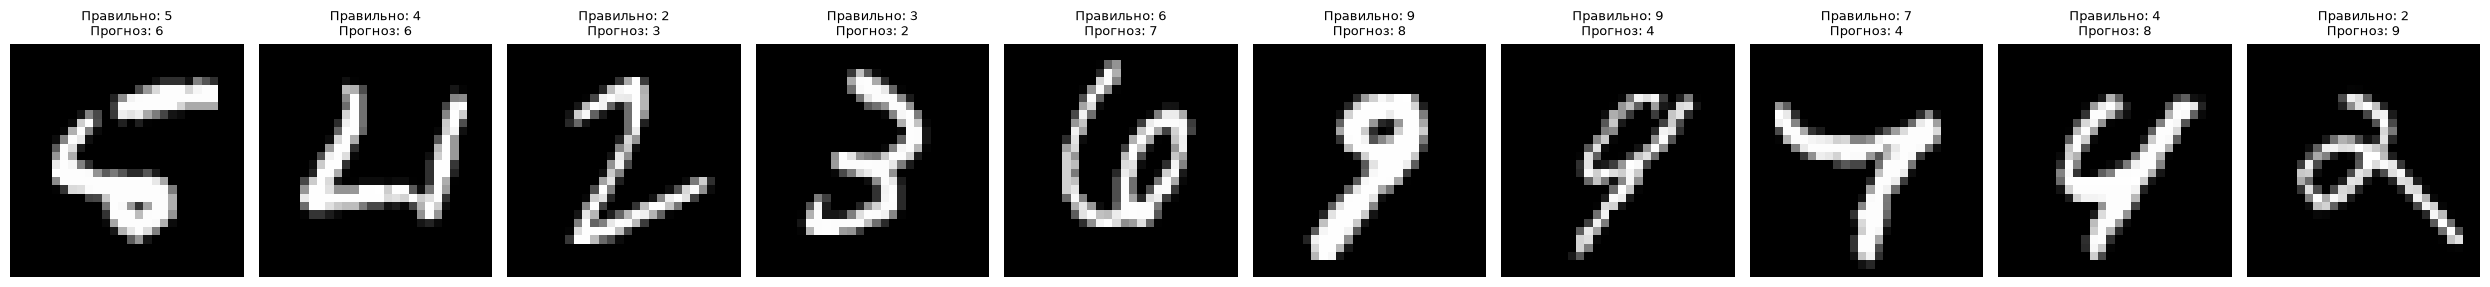

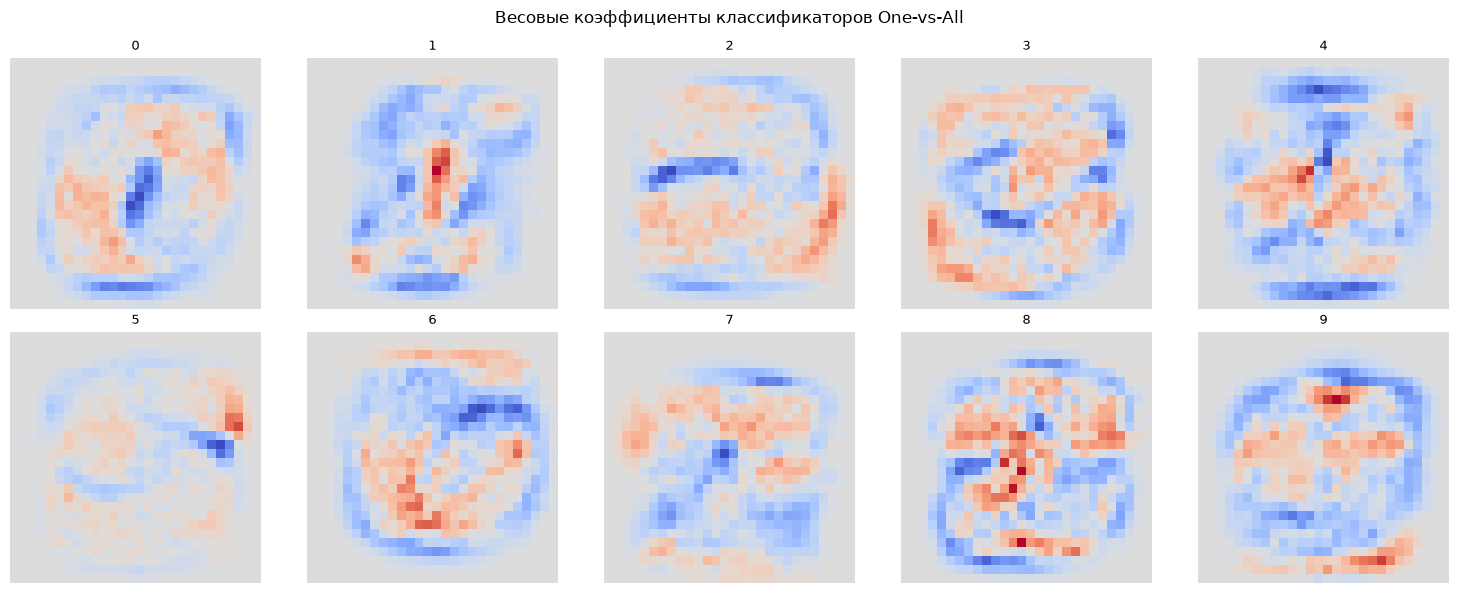


НАБОР ДАННЫХ: Fashion-MNIST
Fashion-MNIST: обучение 60000 изображений, тестирование 10000 изображений, признаков 784
Итерация 1/1000; функция потерь: 16.12315
Итерация 100/1000; функция потерь: 5.05895
Итерация 200/1000; функция потерь: 4.30019
Итерация 300/1000; функция потерь: 3.83873
Итерация 400/1000; функция потерь: 3.89983
Итерация 500/1000; функция потерь: 4.22551
Итерация 600/1000; функция потерь: 3.88949
Итерация 700/1000; функция потерь: 4.07250
Итерация 800/1000; функция потерь: 3.51622
Итерация 900/1000; функция потерь: 4.09103
Итерация 1000/1000; функция потерь: 3.67934

Точность: 75.74%
Правильно распознано: 7574 из 10000
Количество ошибок: 2426
Итераций: 1000
Время загрузки и подготовки: 0.37 сек.
Время обучения: 46.02 сек.
Количество ошибок: 2426


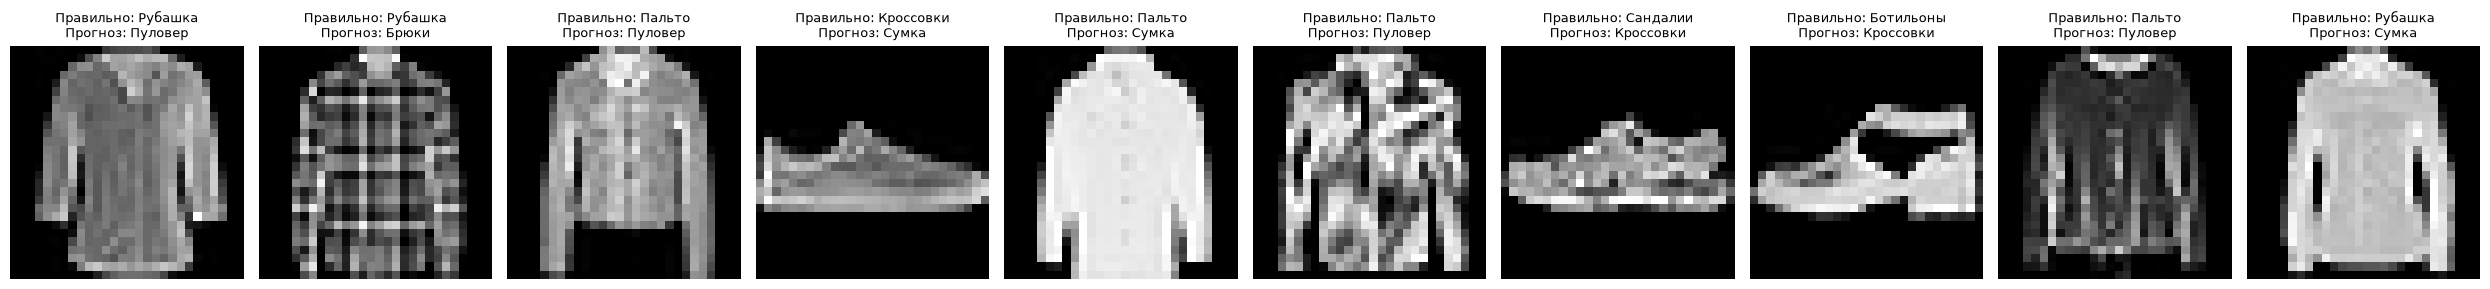

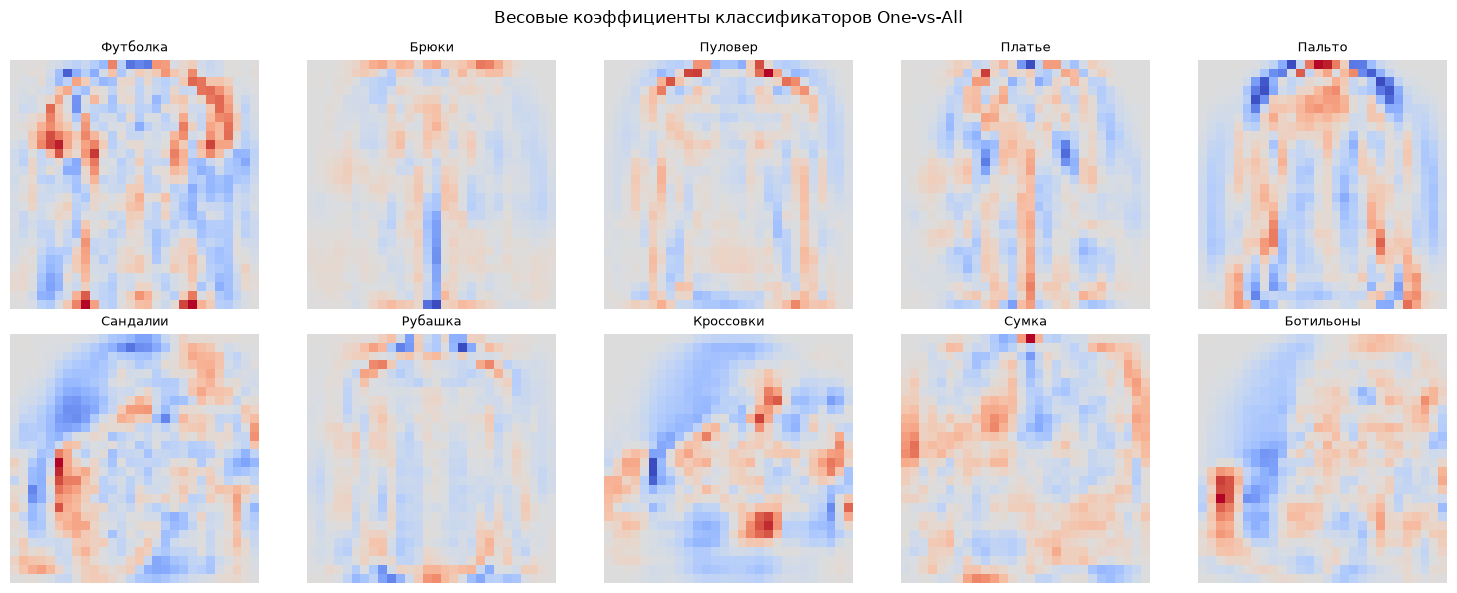


НАБОР ДАННЫХ: CIFAR-10
CIFAR-10: обучение 50000 изображений, тестирование 10000 изображений, признаков 3072
Итерация 1/1000; функция потерь: 16.18741
Итерация 100/1000; функция потерь: 21.09888
Итерация 200/1000; функция потерь: 16.87131
Итерация 300/1000; функция потерь: 31.26691
Итерация 400/1000; функция потерь: 18.29119
Итерация 500/1000; функция потерь: 25.26873
Итерация 600/1000; функция потерь: 16.16190
Итерация 700/1000; функция потерь: 24.87791
Итерация 800/1000; функция потерь: 16.25515
Итерация 900/1000; функция потерь: 21.20944
Итерация 1000/1000; функция потерь: 24.30889

Точность: 19.93%
Правильно распознано: 1993 из 10000
Количество ошибок: 8007
Итераций: 1000
Время загрузки и подготовки: 1.58 сек.
Время обучения: 134.54 сек.
Количество ошибок: 8007


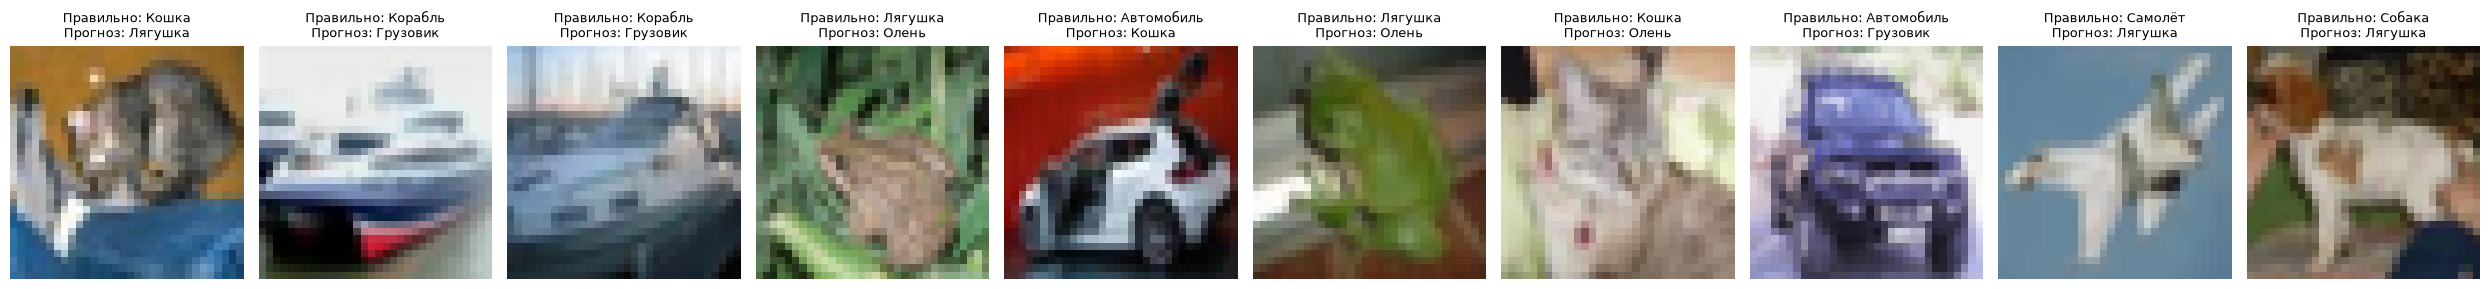

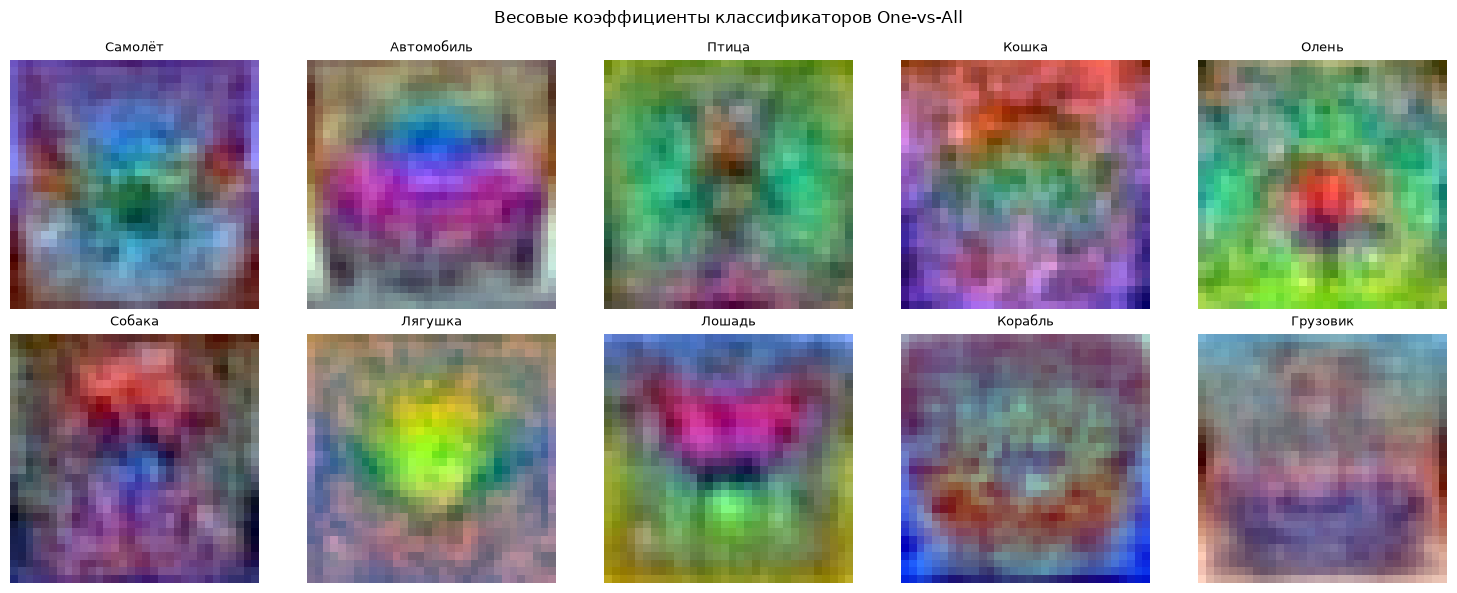


ИТОГОВЫЕ РЕЗУЛЬТАТЫ
Набор данных         Обучение       Тест     Точность     Ошибки     Время обучения
MNIST                   60000      10000       90.72%        928           45.25 сек.
Fashion-MNIST           60000      10000       75.74%       2426           46.02 сек.
CIFAR-10                50000      10000       19.93%       8007          134.54 сек.


In [ ]:
def run_experiment(dataset_name):
    print("\n" + "=" * 70)
    print("НАБОР ДАННЫХ:", dataset_name)
    print("=" * 70)

    load_start = time.perf_counter()
    X_train, y_train, X_test, y_test, test_images, image_shape, class_names = LR.set_data(dataset_name)
    load_time = time.perf_counter() - load_start

    model = LR(alpha=2.5, epsilon=1e-4, max_iter=1000, reg_param=1.0)

    train_start = time.perf_counter()
    model.one_vs_all(X_train, y_train)
    train_time = time.perf_counter() - train_start

    predictions = model.predict(X_test)
    accuracy = float(np.mean(predictions == y_test) * 100.0)
    errors = int(np.sum(predictions != y_test))

    print(f"\nТочность: {accuracy:.2f}%")
    print(f"Правильно распознано: {len(y_test) - errors} из {len(y_test)}")
    print(f"Количество ошибок: {errors}")
    print(f"Итераций: {model.n_iter_}")
    print(f"Время загрузки и подготовки: {load_time:.2f} сек.")
    print(f"Время обучения: {train_time:.2f} сек.")

    model.depict(test_images, y_test, predictions, image_shape, class_names)

    result = {
        "dataset": dataset_name,
        "train_size": len(y_train),
        "test_size": len(y_test),
        "accuracy": accuracy,
        "errors": errors,
        "iterations": model.n_iter_,
        "load_time": load_time,
        "train_time": train_time
    }

    del X_train, X_test, y_train, y_test, test_images, predictions, model
    gc.collect()
    return result


results = []
for dataset in ["MNIST", "Fashion-MNIST", "CIFAR-10"]:
    results.append(run_experiment(dataset))

print("\n" + "=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ")
print("=" * 70)
print(f"{'Набор данных':<18} {'Обучение':>10} {'Тест':>10} {'Точность':>12} {'Ошибки':>10} {'Время обучения':>18}")
for result in results:
    print(
        f"{result['dataset']:<18} "
        f"{result['train_size']:>10} "
        f"{result['test_size']:>10} "
        f"{result['accuracy']:>11.2f}% "
        f"{result['errors']:>10} "
        f"{result['train_time']:>15.2f} сек."
    )